<a href="https://colab.research.google.com/github/akinlayoadeniran/marketing-analytics-ml/blob/main/Akin_Time_Series_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [38]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.datasets import co2
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.linear_model import LinearRegression

#Exercise 1

In [31]:
data = co2.load_pandas().data.copy()
data = data.rename(columns={"co2": "co2_ppm"})
monthly = data["co2_ppm"].resample("MS").mean().interpolate()
monthly.head()

,co2_ppm
1958-03-01,316.100000
1958-04-01,317.200000
1958-05-01,317.433333
1958-06-01,316.529167
1958-07-01,315.625000


#Exercise 2

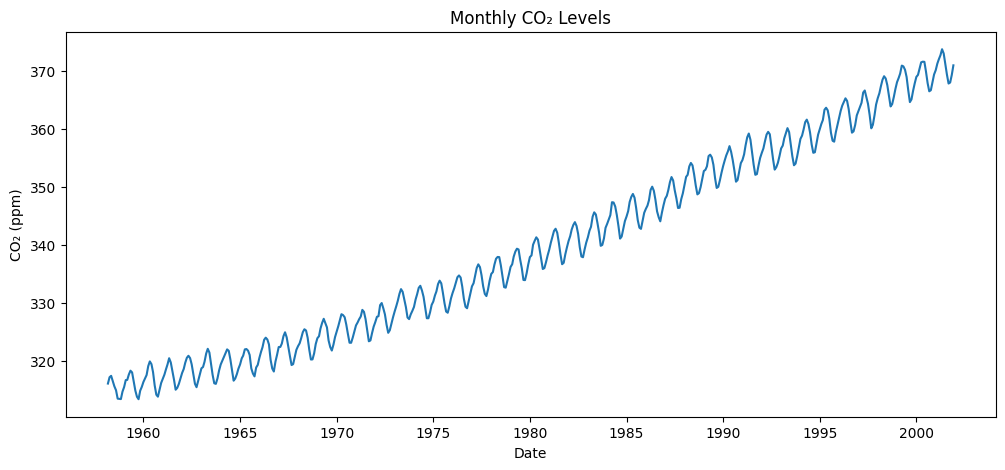

In [32]:
plt.figure(figsize=(12, 5))
plt.plot(monthly)
plt.title("Monthly CO₂ Levels")
plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.show()

1. The series goes up overall. It starts around 315 ppm in 1958 and reaches about 370 ppm by 2001.
2. Yes, there is a repeating pattern. The line goes up and down in small waves, once every year.
3. No, it is not perfectly smooth. The waves are not exactly the same each year, so there is some random variation on top of the trend and the yearly pattern.

#Exercise 3

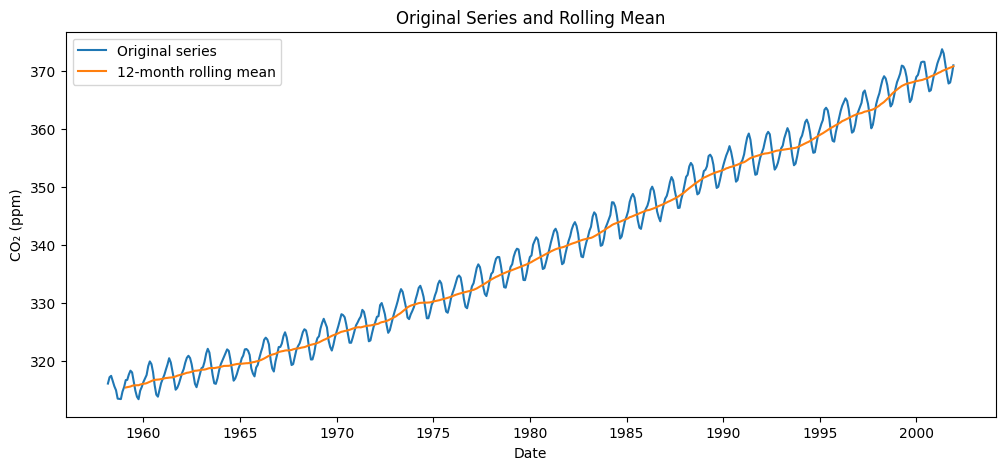

In [33]:
rolling_12 = monthly.rolling(window=12).mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly, label="Original series")
plt.plot(rolling_12, label="12-month rolling mean")
plt.title("Original Series and Rolling Mean")
plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.legend()
plt.show()

The rolling mean is easier to interpret because it smooths out the yearly ups and downs. The original line wiggles every year, which makes it harder to see the overall direction. The 12 month rolling mean averages over a full year, so the seasonal waves cancel out and the smooth upward trend is easy to see.

#Exercise 4

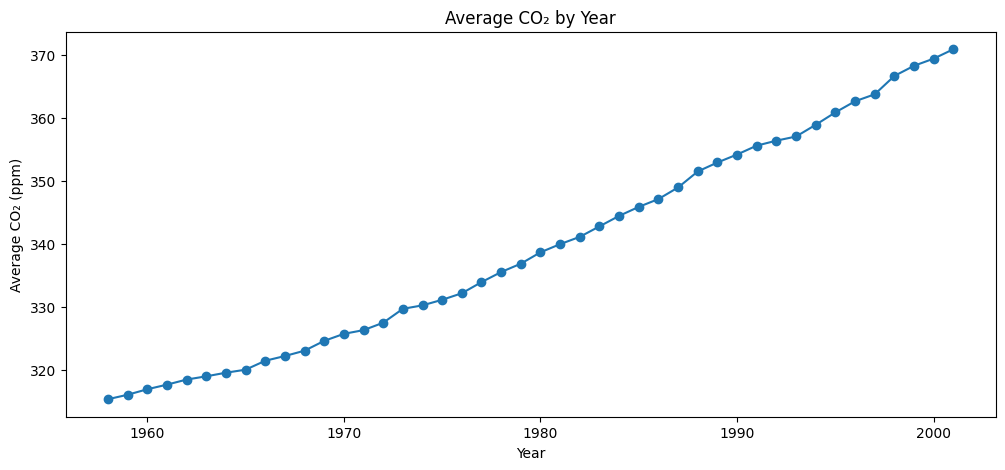

In [34]:
yearly = monthly.resample("Y").mean()
plt.figure(figsize=(12, 5))
plt.plot(yearly.index.year, yearly.values, marker="o")
plt.title("Average CO₂ by Year")
plt.xlabel("Year")
plt.ylabel("Average CO₂ (ppm)")
plt.show()

The yearly averages show a clear long-term upward trend. CO₂ rises almost every year, from about 315 ppm in 1958 to about 370 ppm in 2001. The yearly averages remove the seasonal ups and downs, so the trend is much easier to see than in the raw monthly plot. The line also gets increased over time, which means CO₂ rose faster in the later years than in the early ones.

#Exercise 5

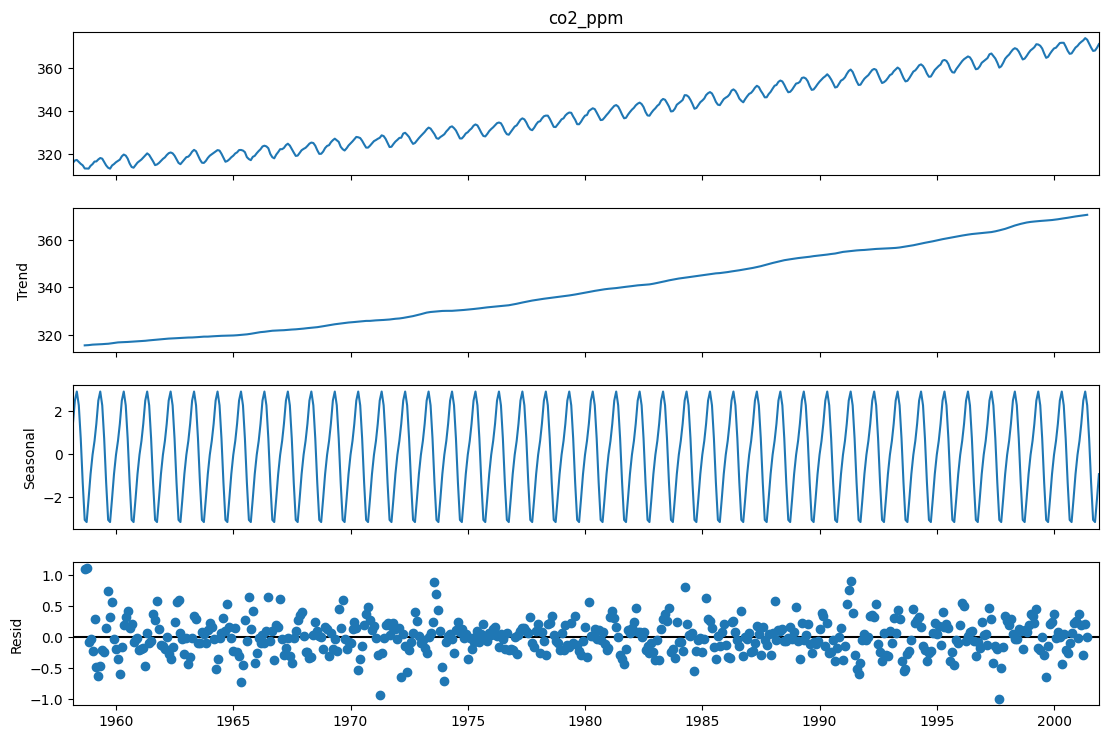

In [35]:
decomposition = seasonal_decompose(monthly, model="additive", period=12)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.show()


Which panel shows the trend? The Trend panel (second). It is the smooth, steadily rising line.
Which panel shows seasonality? The Seasonal panel (third). It repeats the same shape each year.
Which panel looks most random? The Resid panel (bottom). The dots are scattered with no visible pattern, so it is what is left over once the trend and the seasonal pattern are removed.


The Trend panel shows the trend, since it is the smooth line that goes up from about 316 to 371 ppm. The Seasonal panel shows seasonality, because it repeats the same wave every year. The Resid panel looks the most random, because the dots are scattered around zero with no pattern.

#Exercise 6

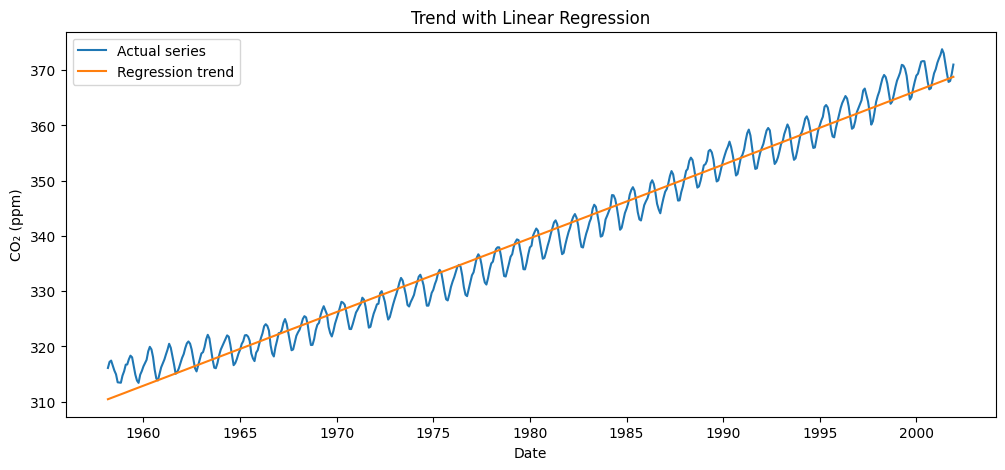

In [36]:
ts = monthly.to_frame(name="co2_ppm").reset_index()
ts["time_index"] = np.arange(len(ts))
X = ts[["time_index"]]
y = ts["co2_ppm"]
model = LinearRegression()
model.fit(X, y)
ts["predicted_trend"] = model.predict(X)
plt.figure(figsize=(12, 5))
plt.plot(ts["index"], ts["co2_ppm"], label="Actual series")
plt.plot(ts["index"], ts["predicted_trend"], label="Regression trend")
plt.title("Trend with Linear Regression")
plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.legend()
plt.show()

The regression line captures the overall upward trend well and shows the average rate at which CO₂ increases. It misses the yearly seasonal waves, because a straight line can not go up and down. It also misses that the trend gets incresing over time: at the start of the series the real data is above the line, and at the end it is too, while the line has the same slope the whole way. A curved line, like a polynomial, would fit the trend better.

#OptionalChallege

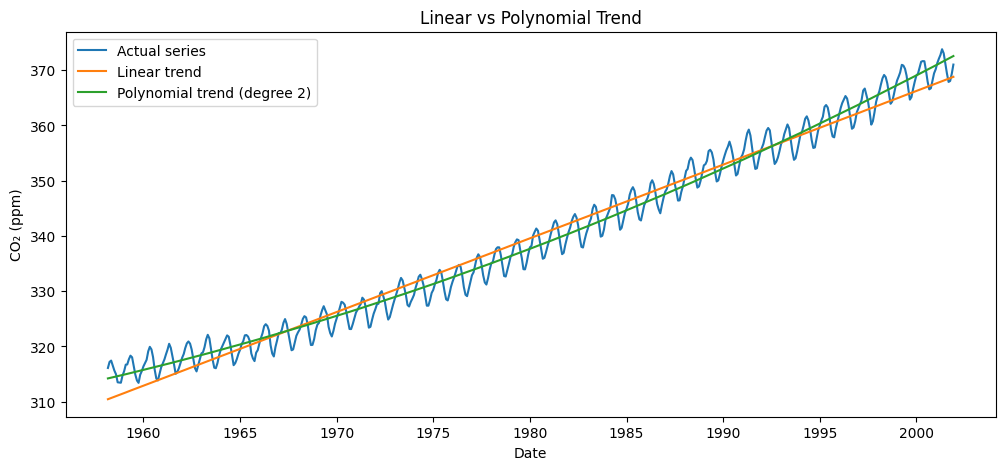

In [37]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

poly_model = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
poly_model.fit(X, y)
ts["poly_trend"] = poly_model.predict(X)

date_col = ts.columns[0]   # the date column (it may be called "index" or "date")

plt.figure(figsize=(12, 5))
plt.plot(ts[date_col], ts["co2_ppm"], label="Actual series")
plt.plot(ts[date_col], ts["predicted_trend"], label="Linear trend")
plt.plot(ts[date_col], ts["poly_trend"], label="Polynomial trend (degree 2)")
plt.title("Linear vs Polynomial Trend")
plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.legend()
plt.show()

I fitted a polynomial regression of degree 2 and compared it with the straight line. The curved line follows the trend better. At the start the straight line was below the real data and at the end it was also below, but the curve stays in the middle of the waves in both places. This is because CO₂ rose faster in the later years, and the polynomial can bend upward while a straight line can’t. Neither line captures the yearly seasonal waves, because both are smooth. A higher degree could fit even more closely, but it might fit the noise in this data instead of the real trend, so a simple curve like degree 2 is enough here.

#Exercise 7

#Relection

The trend in this series is upward. CO₂ rose steadily from about 315 ppm in 1958 to about 370 ppm in 2001, and the rise got faster over time. The seasonal pattern is a wave that repeats every year, moving about 3 ppm above and below the trend. The noise is the small random variation left after removing the trend and seasonality, shown in the residual panel as scattered dots of about ±1 ppm. The method that helped me understand the trend best was the yearly averages, because each point is one year, so the seasonal waves are gone and I can see the trend going up, with almost no noise. The raw plot and the rolling mean also showed the trend, but the yearly averages made it easiest to read.


